<a href="https://colab.research.google.com/github/EthanJF-Physics/MAT422/blob/main/MAT422HW6EthanF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy as scipy
import random
import math
import pandas as pd
from scipy import stats
from scipy.integrate import quad

### 2.4.1 MLE for Random Samples

Maximum likelihood estimation (MLE) is an effective approach for estimating the parameters of a probability distribution by maximizing a likelihood function. The point in the parameter space that maximizes the likelihood function is called the **maximum likelihood estimate**.

**Definition 2.4.1.** Let $X_1, X_2, \dots, X_n$ have joint pmf or pdf

$$
f(x_1, x_2, \dots, x_n; \theta_1, \dots, \theta_m)
$$

where the parameters $\theta_1, \dots, \theta_m$ have unknown values.

When $x_1, \dots, x_n$ are the observed sample values and the above function is regarded as a function of $\theta_1, \dots, \theta_m$, it is called the **likelihood function**.

The **maximum likelihood estimates (MLEs)** $\hat{\theta}_1, \dots, \hat{\theta}_m$ are those values of the $\theta_i$'s that maximize the likelihood function, so that

$$
f(x_1, \dots, x_n; \hat{\theta}_1, \dots, \hat{\theta}_m)
\geq
f(x_1, \dots, x_n; \theta_1, \dots, \theta_m)
$$

for all $\theta_1, \dots, \theta_m$.

When the random variables $X_i$ are substituted in place of the observed values $x_i$, the resulting quantities are called the **maximum likelihood estimators**.


1: Random Sample
Sample: [11.49014246  9.5852071  11.94306561 14.56908957  9.29753988  9.29758913
 14.73763845 12.30230419  8.59157684 11.62768013  8.60974692  8.60281074
 10.72588681  4.26015927  4.8252465   8.31313741  6.96150664 10.942742
  7.27592777  5.7630889  14.39694631  9.3226711  10.20258461  5.72575544
  8.36685183 10.33276777  6.54701927 11.12709406  8.19808393  9.12491875
  8.19488016 15.55683455  9.95950833  6.82686721 12.46763474  6.33746905
 10.62659079  4.12098963  6.01544185 10.59058371 12.21539974 10.51410484
  9.65305515  9.09668891  5.56443403  7.84046737  8.61808369 13.17136668
 11.03085487  4.71087953 10.97225191  8.84475316  7.969234   11.83502887
 13.09299857 12.79384036  7.48234743  9.07236287 10.99379029 12.92663538
  8.56247729  9.44302307  6.68099508  6.41138013 12.43757747 14.06872009
  9.78396964 13.01059869 11.08490808  8.06464074 11.08418682 14.6141097
  9.89252188 14.69393097  2.14076469 12.46570751 10.2611412   9.10297795
 10.27528233  4.03729326  9.3

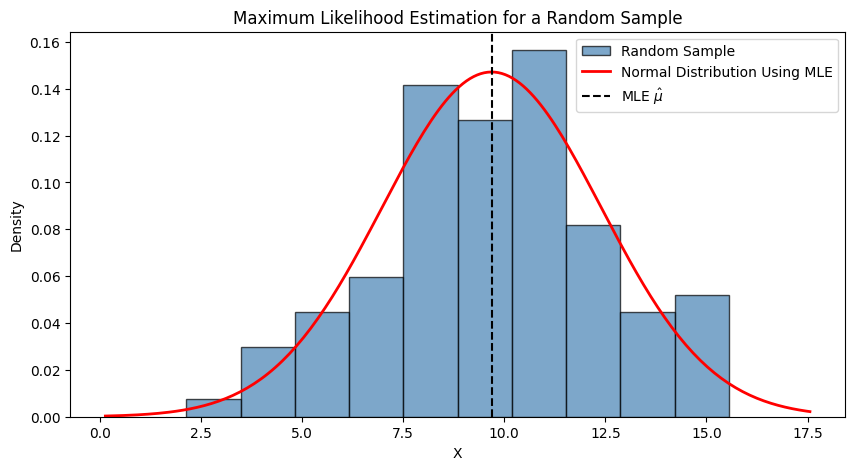

In [2]:
# Generate a random sample
mu = 10
sigma = 3
n = 100
np.random.seed(42)
sample = np.random.normal(mu, sigma, n)
print("1: Random Sample")
print("Sample:", sample)
print("Sample size:", n)

# Maximum likelihood estimate for mu
mu_hat = np.mean(sample)
print("\n2: MLE for mu")
print("True mu:", mu)
print("MLE mu_hat:", mu_hat)
# Maximum likelihood estimate for sigma^2
sigma2_hat = np.sum((sample - mu_hat) ** 2) / n
print("\n3: MLE for sigma^2")
print("True sigma^2:", sigma**2)
print("MLE sigma^2_hat:", sigma2_hat)
# Maximum likelihood estimate for sigma
sigma_hat = np.sqrt(sigma2_hat)
print("\n4: MLE for sigma")
print("True sigma:", sigma)
print("MLE sigma_hat:", sigma_hat)

# Plot the Sample and MLE Normal Distribution
x = np.linspace(
    np.min(sample) - 2,
    np.max(sample) + 2,
    200
)
fitted_pdf = stats.norm.pdf(
    x,
    loc=mu_hat,
    scale=sigma_hat
)
# Plot
plt.figure(figsize=(10, 5))
plt.hist(
    sample,
    bins=10,
    density=True,
    color='steelblue',
    edgecolor='black',
    alpha=0.7,
    label='Random Sample'
)
plt.plot(
    x,
    fitted_pdf,
    color='red',
    linewidth=2,
    label='Normal Distribution Using MLE'
)
plt.axvline(
    mu_hat,
    color='black',
    linestyle='--',
    label=r'MLE $\hat{\mu}$'
)
plt.title('Maximum Likelihood Estimation for a Random Sample')
plt.xlabel('X')
plt.ylabel('Density')
plt.legend()
plt.show()


### 2.4.2 Linear regression

 Consider that we have $n$ points, each of which is drawn in an independent and identically distributed (i.i.d.) way from the normal distribution. For a given $\mu, \sigma^2$, the probability of those $n$ points being drawn define the likelihood function, which are just the multiplication of $n$ normal probability density functions (pdf) (because they are independent):

$$ \mathscr{P}(\mu \mid y) = \prod_{i=1}^n P_Y(y_i \mid \mu, \sigma^2) = \prod_{i=1}^n \frac{1}{\sigma \sqrt{2\pi}} e^{-\frac{(y_i-\mu)^2}{2\sigma^2}} \qquad (2.4.2) $$

Now understand that $y$ is a random variable,
$$ y_i = \hat{y}_i + \varepsilon, $$
where $\varepsilon \sim N(0, \sigma^2)$. Thus $y_i$ is a normal variable with mean as a linear function of $\mathbf{x}$ and a fixed standard deviation:
$$ y_i \sim N(\hat{y}_i, \sigma^2) . \qquad (2.4.3) $$

As a result, for each $y_i$, we choose $\mu$ in the normal distributions in (2.4.2) as
$$ \mu_i = \hat{y}_i. $$

Hence we derive the maximum likelihood estimate
$$ \begin{aligned}
\hat{\beta} &= \arg\max_{\beta} \mathscr{P}(\beta \mid y) = \arg\max_{\beta} \prod_{i=1}^n \frac{1}{\sigma \sqrt{2\pi}} e^{-\frac{(y_i-\hat{y}_i)^2}{2\sigma^2}} \\
&= \arg\max_{\beta} \log \left( \prod_{i=1}^n \frac{1}{\sigma \sqrt{2\pi}} e^{-\frac{(y_i-\hat{y}_i)^2}{2\sigma^2}} \right) \\
&= \arg\max_{\beta} \sum_{i=1}^n \left[ \log \left( \frac{1}{\sigma \sqrt{2\pi}} \right) + \log \left( e^{-\frac{(y_i-\hat{y}_i)^2}{2\sigma^2}} \right) \right] \qquad (2.4.4) \\
&= \arg\max_{\beta} \sum_{i=1}^n \log \left( e^{-\frac{(y_i-\hat{y}_i)^2}{2\sigma^2}} \right) \\
&= \arg\max_{\beta} \sum_{i=1}^n -\frac{(y_i - \hat{y}_i)^2}{2\sigma^2} \\
&= \arg\min_{\beta} \sum_{i=1}^n (y_i - \hat{y}_i)^2,
\end{aligned} $$
which is exactly the least square problem we discussed before.


1: Random Data
Sample size: 100
True beta_0: 2.0
True beta_1: 3.5
True sigma: 2.5

2: MLE / Least Squares Estimates
True beta_0: 2.0
MLE beta_0_hat: 2.5377403938668754
True beta_1: 3.5
MLE beta_1_hat: 3.3850566932192425

3: Predicted Values
First 5 observed y values: [15.32652183 34.52748235 27.8491899  17.98412466  6.9114727 ]
First 5 predicted y values: [15.21613576 34.71995866 27.31615032 22.80266948  7.81905982]


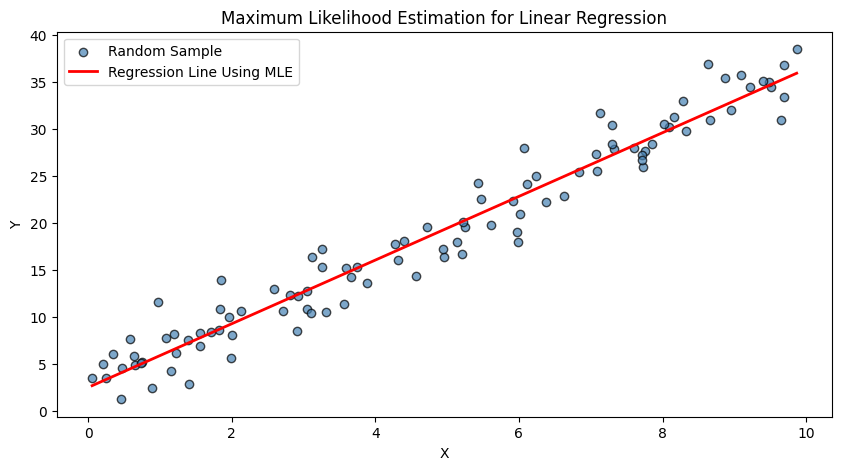

In [3]:
# Generate a Random Sample
np.random.seed(42)
n = 100
true_beta_0 = 2.0
true_beta_1 = 3.5
true_sigma = 2.5
X_raw = np.random.uniform(0, 10, n)
epsilon = np.random.normal(0, true_sigma, n)
y = true_beta_0 + true_beta_1 * X_raw + epsilon
print("1: Random Data")
print("Sample size:", n)
print("True beta_0:", true_beta_0)
print("True beta_1:", true_beta_1)
print("True sigma:", true_sigma)

# Maximum Likelihood / Least Squares Estimate for beta
X = np.column_stack((np.ones(n), X_raw))
beta_hat = np.linalg.inv(X.T @ X) @ X.T @ y
print("\n2: MLE / Least Squares Estimates")
print("True beta_0:", true_beta_0)
print("MLE beta_0_hat:", beta_hat[0])
print("True beta_1:", true_beta_1)
print("MLE beta_1_hat:", beta_hat[1])

# Calculate predicted values
y_hat = X @ beta_hat
print("\n3: Predicted Values")
print("First 5 observed y values:", y[:5])
print("First 5 predicted y values:", y_hat[:5])

# Plot the Data and MLE Regression Line
x_line = np.linspace(
    np.min(X_raw),
    np.max(X_raw),
    100
)
y_line = beta_hat[0] + beta_hat[1] * x_line
plt.figure(figsize=(10, 5))
plt.scatter(
    X_raw,
    y,
    color='steelblue',
    edgecolor='black',
    alpha=0.7,
    label='Random Sample'
)
plt.plot(
    x_line,
    y_line,
    color='red',
    linewidth=2,
    label='Regression Line Using MLE'
)
plt.title('Maximum Likelihood Estimation for Linear Regression')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()
